In [ ]:
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [ ]:
#Parâmetros NF-kB
nfkb0 = 0.25
gammaNF = 2
NF_50 = 0.3
h = 0.55
s = 0.8
tau = 10
S1 = 1
#t = np.arange(0.000001, 300, 1)
#o t corresponde a um intervalo de 1 a 100, de 1 em 1
#diferente do range, assim dá pra lidar com float

#Parâmetros NLRP3
alpha1 = 0.07
S2 = 1
k1 = 0.7
novodelta1 = 0.0025
#j * delta1 = 1.25 * 0.002 = 0.0025
#delta1 = 0.002
k2 = 1

#Parâmetros ASC
k3 = 0.04
a = 1
b = 2
c = 1000

#Caspase-1
k4 = 0.03
C1_50 = 0.3
gammaC1 = 2

#Gardermina
Gnovo = 0.08
#Gnovo = G * k6 (k6 = 1/min)
#Valor anterior de G: 0.1

#Citocinas
alpha3 = 0.06
alpha4 = 1
alpha5 = 1
k5 = 1
delta2 = 0.004
k6 = 1
#delta2 = 0.004

#novidades
j = 0.7
#j representa a fração de IL1B celular que vira extra

In [ ]:
#Função NF_kBn
def nfkbn(t):
  #np.where para aplicar a lógica condicional elemento a elemento, p n dar aquele erro de valor único
  #se t for 0, retorna 0.25, senao, calcula a fórmula

  t_log = np.where(t == 0, 1.0, t)
  #isso quer dizer: p cada elemento, se t==0, use 1; senao, use t

  resultado = S1 * h * np.exp(-(np.log(t_log/tau) ** 2) / s) + nfkb0

  return np.where(t == 0, 0.25, resultado)

In [ ]:
#Hill
def hill(x, K, n):
  return (x**n) / (K**n + x**n)


In [ ]:
#Função sinalizadora de ASC

def sinal(NLRP3o, a, b, c):
  return 1/(1 + (((NLRP3o + a)/b) ** (-c)))

Juntar: IL1Bc e IL1Be -> Com que taxa uma vira a outra? Tipo, pegar a eq da intra e multiplicar pela taxa com que ela sai da célula, acaba q é quase o q rolou com o NLRP3

In [ ]:
def edos(t, y):
  NLRP3a = y[0]
  NLRP3o = y[1]
  ASCb = y[2]
  C1 = y[3]

  IL18c = y[4]
  IL18e = y[5]

  proIL1B = y[6]
  IL1Be = y[7]

  dNLRP3a_dt = alpha1 * hill(nfkbn(t) - nfkb0, NF_50, gammaNF) - (k2 * (NLRP3a)**2) - (novodelta1*NLRP3a)

  dNLRP3o_dt = (k2 * (NLRP3a)**2)

  dASCb_dt = (
      k3 * sinal(NLRP3o, a, b, c) * (1 - ASCb)
  )

  dC1_dt = (
      k4 * ASCb * (1-C1)
  )

  dIL18c_dt = (
      alpha5 * hill(C1, C1_50, gammaC1) * (1-(IL18c+IL18e)) - Gnovo*IL18c
  )

  dIL18e_dt =(
      Gnovo*IL18c
  )

  dproIL1B_dt = (
      (hill(nfkbn(t) - nfkb0, NF_50, gammaNF)*alpha3) - (hill(C1, C1_50, gammaC1)*alpha4*proIL1B) - (delta2*proIL1B)
  )

  dIL1Be_dt = (
      j*(hill(C1, C1_50, gammaC1)*alpha4*proIL1B)
  )

  return [dNLRP3a_dt, dNLRP3o_dt, dASCb_dt, dC1_dt, dIL18c_dt, dIL18e_dt, dproIL1B_dt, dIL1Be_dt]

dproIL1B_dt = (
      (hill(nfkbn(t) - nfkb0, NF_50, gammaNF)*alpha3) - (hill(C1, C1_50, gammaC1)*alpha4*proIL1B) - (delta2*proIL1B)
  )

  dIL1Be_dt = (
      j*(hill(C1, C1_50, gammaC1)*alpha4*proIL1B)
  )

In [ ]:
valores_iniciais = np.array([0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]) #convertendo para array de floats
t_span = np.array([0.00, 300.0]) #convertendo para array de floats

solucao = solve_ivp(
    edos, t_span, valores_iniciais, method="BDF", rtol=1e-4,
    atol=1e-4)

In [ ]:
#Salvar os resultadps pra poder comparar

resultado = pd.DataFrame({
    "tempo": solucao.t,
    "NFkBn": nfkbn(solucao.t),
    "NLRP3a": solucao.y[0],
    "NLRP3o": solucao.y[1],
    "ASCb": solucao.y[2],
    "C1": solucao.y[3],
    "IL18c": solucao.y[4],
    "IL18e": solucao.y[5],
    "proIL1B": solucao.y[6],
    "IL1Be": solucao.y[7],



})

resultado.to_csv("resultado_simplificado.csv", index=False)

#baixar o arquivo gerado:
#from google.colab import files
#files.download("resultado_simplificado.csv")

In [ ]:
#modelo simplificado
modelo = pd.read_csv("resultado_simplificado.csv")

In [ ]:
#dicionário
comparacoes = {
    "NFkBn": "fator_nuclear.csv",
    "NLRP3a": "nlrp3a.csv",
    "NLRP3o": "nlrp3o.csv",
    "ASCb": "ascb.csv",
    "C1": "c1.csv",
    "IL18c": "il18c.csv",
    "IL18e": "il18e.csv",
    "proIL1B": "proil1b.csv",
    "IL1Be": "b.csv"

    }

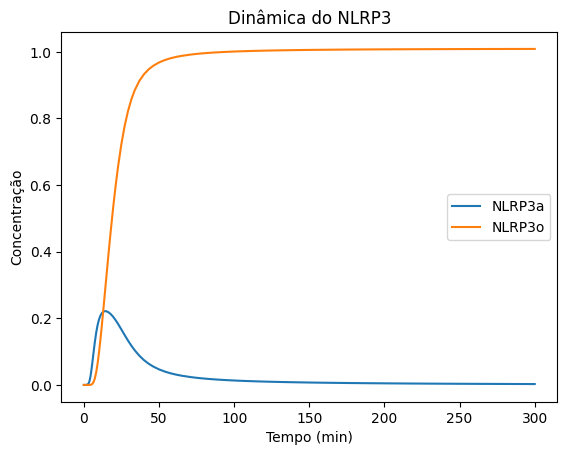

In [ ]:
plt.plot(solucao.t, solucao.y[0], label="NLRP3a")
plt.plot(solucao.t, solucao.y[1], label="NLRP3o")
plt.legend()
plt.xlabel('Tempo (min)')
plt.ylabel('Concentração')
plt.title("Dinâmica do NLRP3")
plt.show()

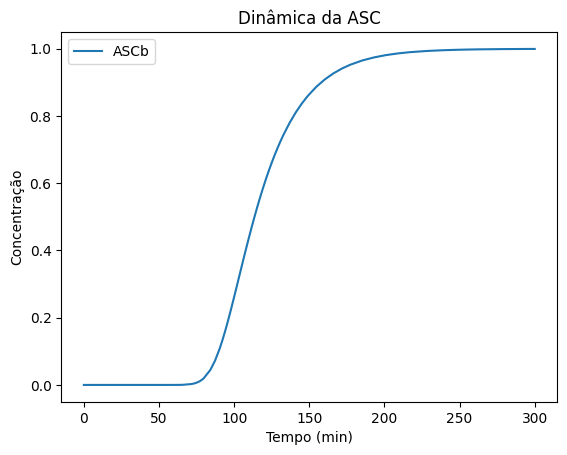

In [ ]:
plt.plot(solucao.t, solucao.y[2], label="ASCb")
plt.legend()
plt.xlabel('Tempo (min)')
plt.ylabel('Concentração')
plt.title("Dinâmica da ASC")
plt.show()

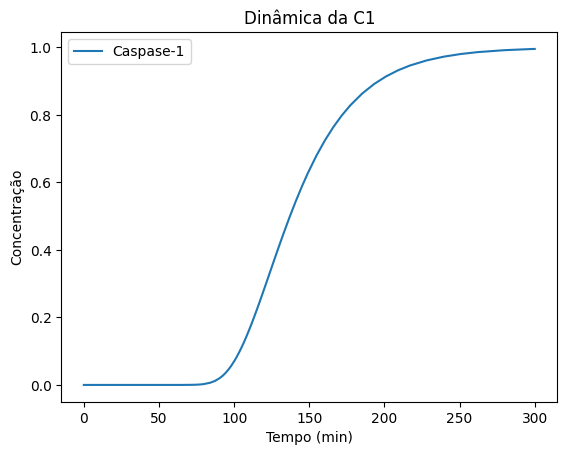

In [ ]:
plt.plot(solucao.t, solucao.y[3], label="Caspase-1")
plt.legend()
plt.xlabel('Tempo (min)')
plt.ylabel('Concentração')
plt.title("Dinâmica da C1")
plt.show()

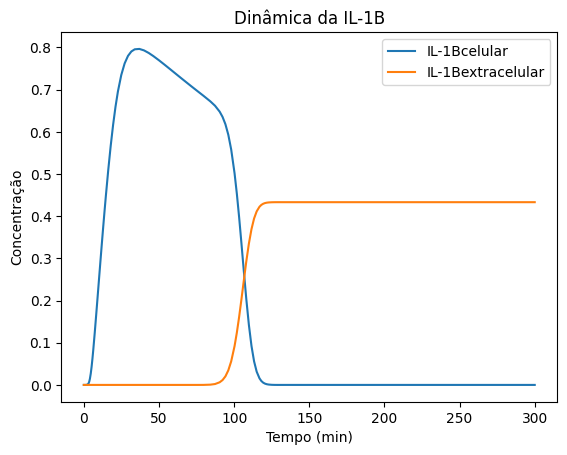

In [ ]:
plt.plot(solucao.t, solucao.y[6], label="IL-1Bcelular")
plt.plot(solucao.t, solucao.y[7], label="IL-1Bextracelular")
plt.legend()
plt.xlabel('Tempo (min)')
plt.ylabel('Concentração')
plt.title("Dinâmica da IL-1B")
plt.show()

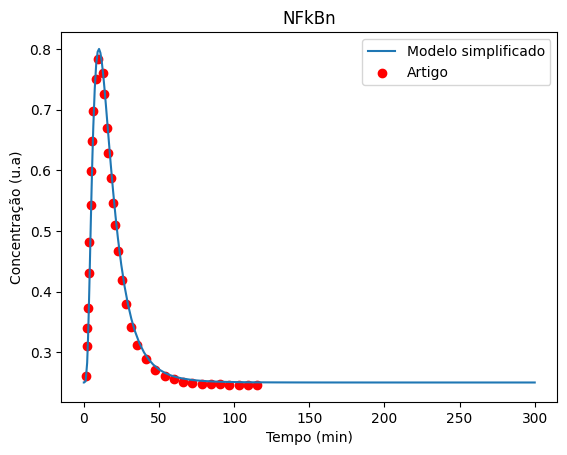

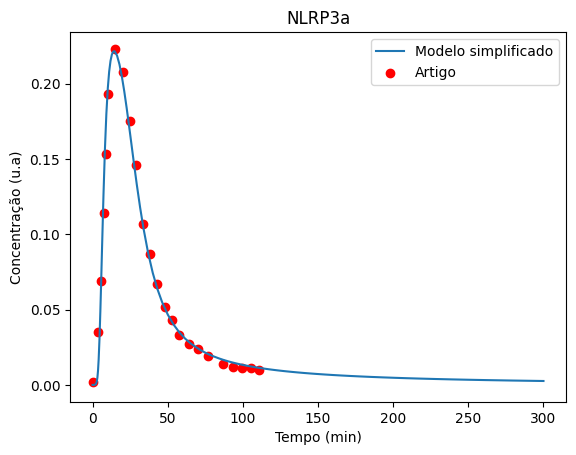

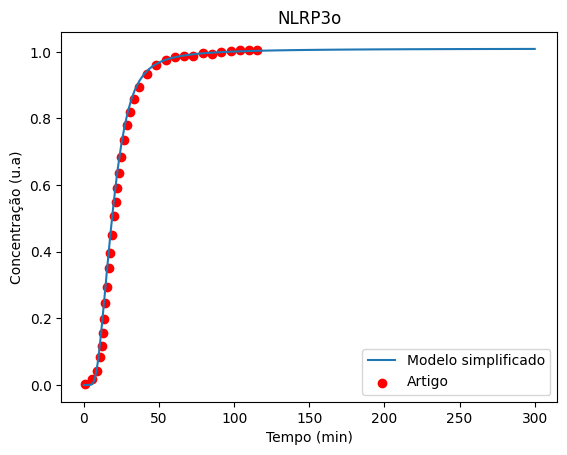

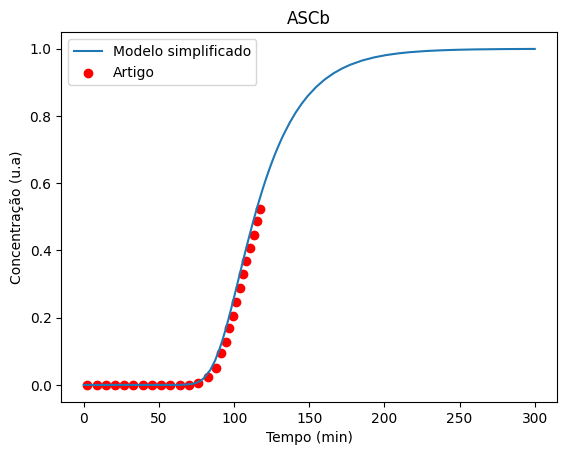

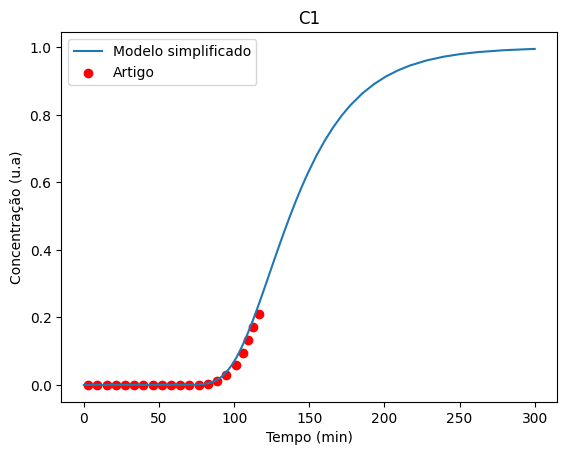

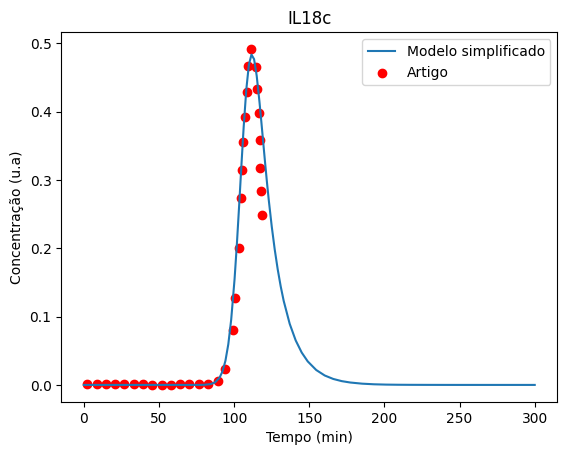

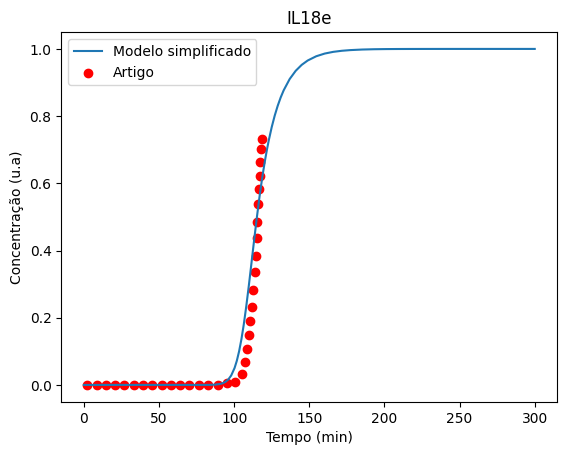

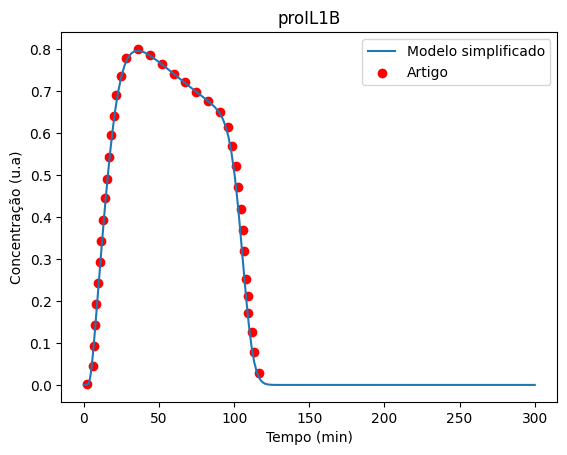

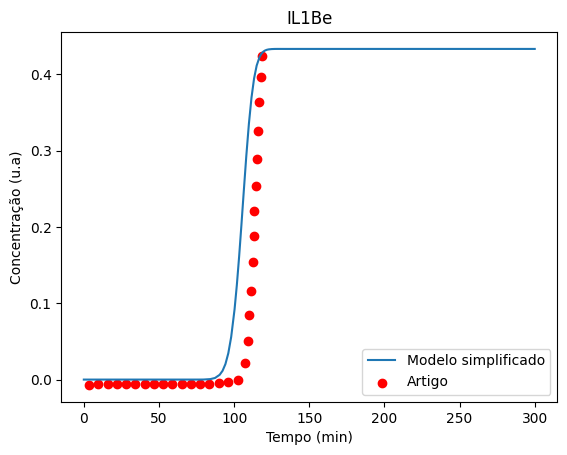

In [ ]:
for variavel, arquivo in comparacoes.items():
  artigo = pd.read_csv(
  arquivo,
  sep = ";",
  decimal = ",",
  header = None
    #pq na tabela do webplot ";" separa falores e "," é separador decimal
    )

  tempo_artigo = artigo.iloc[:,0] #integer location[linha, coluna]
  valor_artigo = artigo.iloc[:,1] #ent aq significa: tds as linhas da 1 coluna
  tempo_modelo = modelo["tempo"]
  valor_modelo = modelo[variavel]

  plt.plot(tempo_modelo, valor_modelo, label="Modelo simplificado")
  plt.scatter(tempo_artigo, valor_artigo, color="red", label="Artigo")

  plt.title(variavel)
  plt.xlabel("Tempo (min)")
  plt.ylabel("Concentração (u.a)")
  plt.legend()
  plt.show()

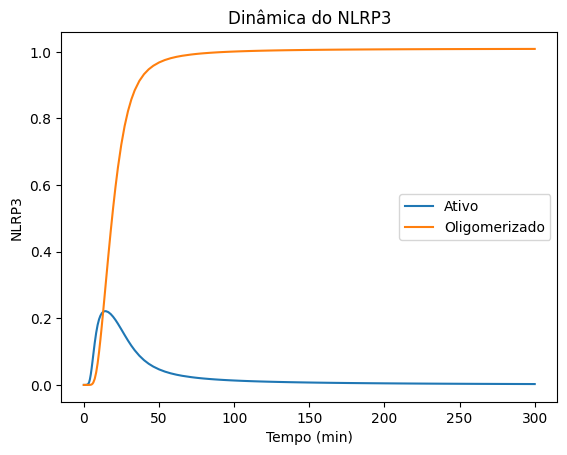

In [ ]:
plt.plot(solucao.t, solucao.y[0], label="Ativo")
plt.plot(solucao.t, solucao.y[1], label="Oligomerizado")
plt.legend()
plt.xlabel('Tempo (min)')
plt.ylabel('NLRP3')
plt.title("Dinâmica do NLRP3")
plt.show()

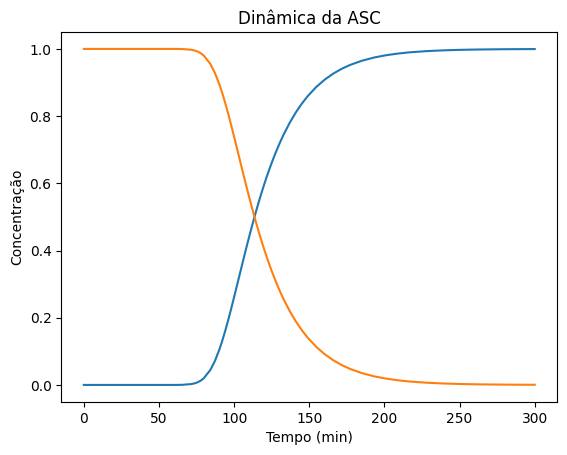

In [ ]:
plt.plot(solucao.t, solucao.y[2], label="ASC ligada")
#A ASC livre é 1-ASCb:
plt.plot(solucao.t, 1-(solucao.y[2]), label = "ASC livre")
plt.xlabel('Tempo (min)')
plt.ylabel('Concentração')
plt.title("Dinâmica da ASC")
plt.show()

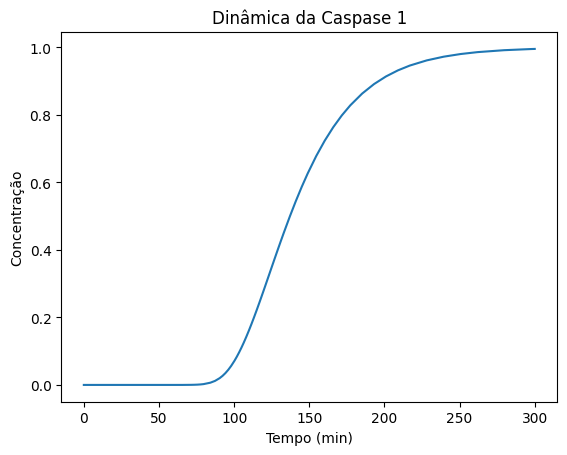

In [ ]:
plt.plot(solucao.t, solucao.y[3], label="Caspase 1 (ativada)")
plt.xlabel('Tempo (min)')
plt.ylabel('Concentração')
plt.title("Dinâmica da Caspase 1")
plt.show()

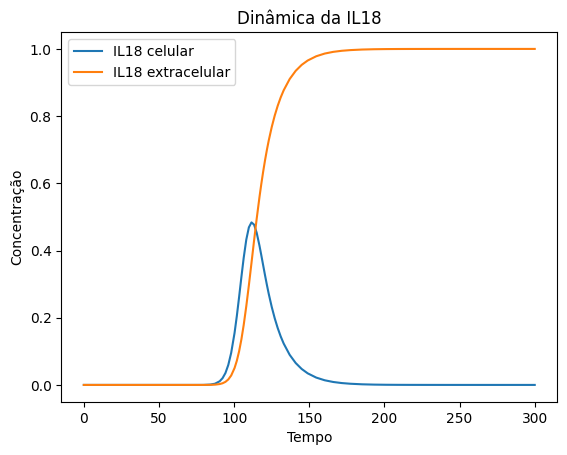

In [ ]:
plt.plot(solucao.t, solucao.y[4], label="IL18 celular")
plt.plot(solucao.t, solucao.y[5], label="IL18 extracelular")
plt.xlabel('Tempo')
plt.ylabel('Concentração')
plt.title("Dinâmica da IL18")
plt.legend()
plt.show()

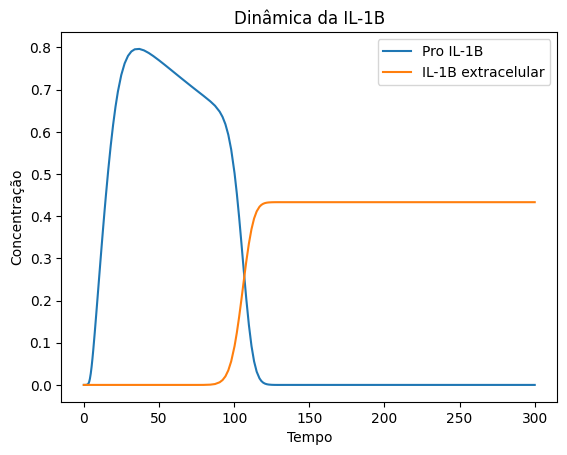

In [ ]:
plt.plot(solucao.t, solucao.y[6], label="Pro IL-1B")
plt.plot(solucao.t, solucao.y[7], label="IL-1B extracelular")
plt.xlabel('Tempo')
plt.ylabel('Concentração')
plt.title("Dinâmica da IL-1B")
plt.legend()
plt.show()


EQUAÇÕES DA IL1B - MODELO COMPLETO:
dproIL1B_dt = (
      (hill(nfkbn(t) - nfkb0, NF_50, gammaNF)*alpha3) - (hill(C1, C1_50, gammaC1)*alpha4*proIL1B) - (delta2*proIL1B)
  )

  dIL1Bc_dt = (
      (hill(C1, C1_50, gammaC1)*alpha4*proIL1B) - (k5 *  G * IL1Bc) - (delta2*IL1Bc)
  )

  dIL1Be_dt = (
      k5 * G * IL1Bc
  )